In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

df = pd.read_csv("data.csv")
print("Shape:", df.shape)
print(df["target"].value_counts())
df.head()

Shape: (19719, 23)
target
Moderate           8452
Resilient          6163
Overcontroller     2829
Undercontroller    2275
Name: count, dtype: int64


,N6,N8,N7,N1,N9,N10,N3,N5,E3,N2,...,E4,age,C4,E1,A4,E10,E9,gender,hand,target
0,1,1,1,1,1,1,2,1,5,5,...,2,53,1,4,5,1,5,Male,Right,Resilient
1,4,2,3,2,2,4,4,3,3,3,...,3,46,2,2,4,5,1,Female,Right,Moderate
2,5,5,5,5,5,5,5,5,1,1,...,4,14,1,5,5,1,5,Female,Right,Moderate
3,5,5,5,5,4,5,4,4,2,4,...,4,19,5,2,4,5,4,Female,Right,Overcontroller
4,3,3,3,3,3,4,3,3,3,3,...,3,25,3,3,5,5,3,Female,Right,Moderate


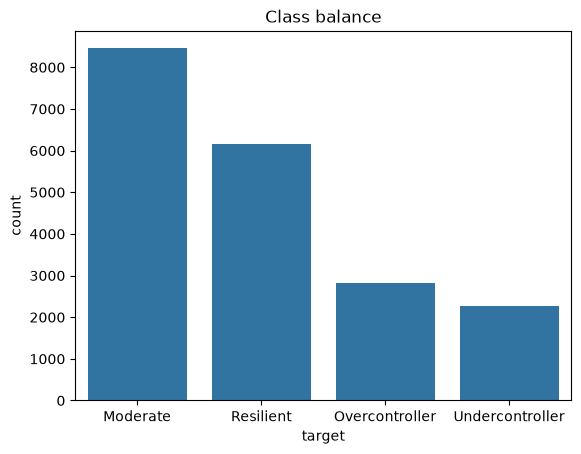

target
Moderate           0.429
Resilient          0.313
Overcontroller     0.143
Undercontroller    0.115
Name: proportion, dtype: float64

In [2]:
order = df["target"].value_counts().index
sns.countplot(data=df, x="target", order=order)
plt.title("Class balance"); plt.show()
df["target"].value_counts(normalize=True).round(3)

In [3]:
print(df.isna().sum()[lambda s: s > 0])
df.dtypes.value_counts()

gender     24
hand      100
dtype: int64


int64    20
str       3
Name: count, dtype: int64

In [4]:
items = [c for c in df.columns if c not in ["age", "gender", "hand", "target"]]
print(df[items].stack().value_counts().sort_index())
print("Rows with all 19 items equal to 0:", (df[items] == 0).all(axis=1).sum())

0       19
1    52001
2    76600
3    82454
4    91044
5    72543
Name: count, dtype: int64
Rows with all 19 items equal to 0: 1


count    1.971900e+04
mean     5.076703e+04
std      7.121272e+06
min      1.300000e+01
25%      1.800000e+01
50%      2.200000e+01
75%      3.100000e+01
max      1.000000e+09
Name: age, dtype: float64
Ages above 100: 83
[np.int64(118), np.int64(188), np.int64(191), np.int64(208), np.int64(211), np.int64(223), np.int64(266), np.int64(1961), np.int64(1964), np.int64(1968)] ...


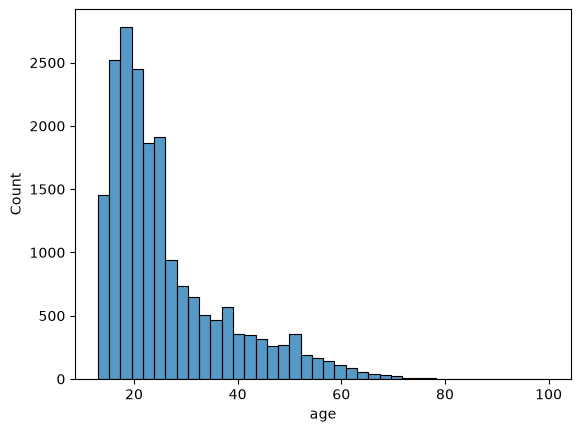

In [5]:
print(df["age"].describe())
print("Ages above 100:", (df["age"] > 100).sum())
print(sorted(df.loc[df["age"] > 100, "age"].unique())[:10], "...")
sns.histplot(df.loc[df["age"].between(13, 100), "age"], bins=40); plt.show()

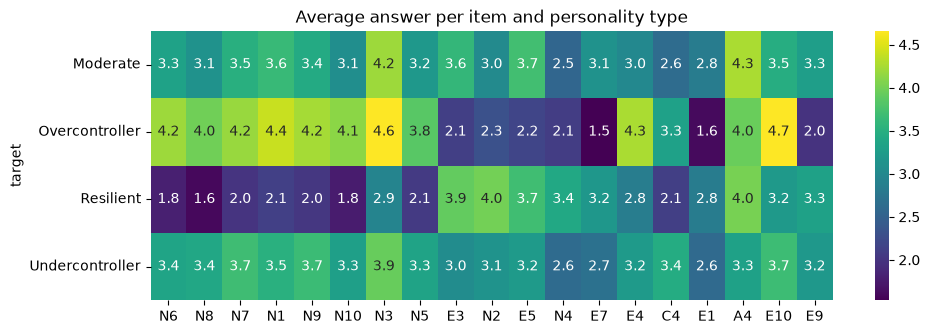

In [6]:
clean = df[df["age"].between(13, 100) & ~(df[items] == 0).all(axis=1)]
means = clean.groupby("target")[items].mean()
plt.figure(figsize=(11, 3.5))
sns.heatmap(means, cmap="viridis", annot=True, fmt=".1f")
plt.title("Average answer per item and personality type"); plt.show()

In [9]:
from utils import load_clean_data, split_xy, build_preprocessor

df = load_clean_data()
X, y = split_xy(df)
print(df.shape)           # (19635, 23): 84 rows removed

preprocessor = build_preprocessor(X)
X_prepared = preprocessor.fit_transform(X)
print("Before:", X.shape, " After:", X_prepared.shape)   # 22 -> 26 columns
print(preprocessor.get_feature_names_out()[-7:])         # age + the one-hot columns

ImportError: cannot import name 'load_clean_data' from 'utils' (/Users/ajaykumar/Documents/MSIT/MLStuff/personality-project/utils.py)